(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Missing values: 0


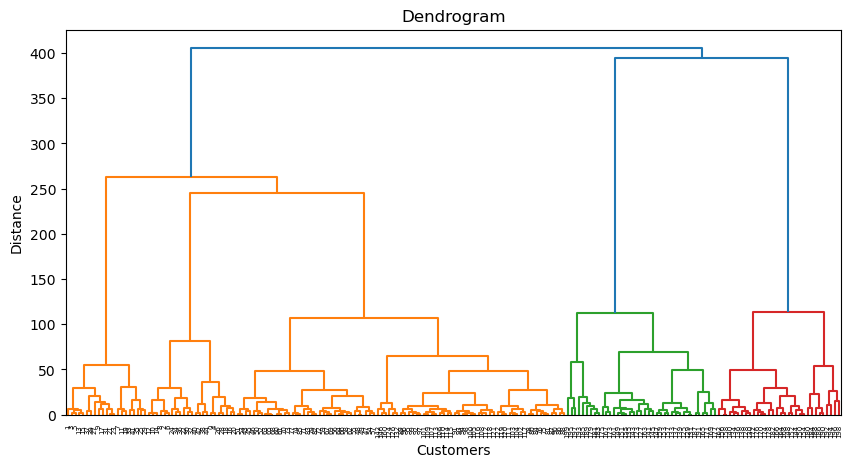

     Annual Income (k$)  Spending Score (1-100)  Cluster
0                    15                      39        4
1                    15                      81        3
2                    16                       6        4
3                    16                      77        3
4                    17                      40        4
..                  ...                     ...      ...
195                 120                      79        2
196                 126                      28        0
197                 126                      74        2
198                 137                      18        0
199                 137                      83        2

[200 rows x 3 columns]


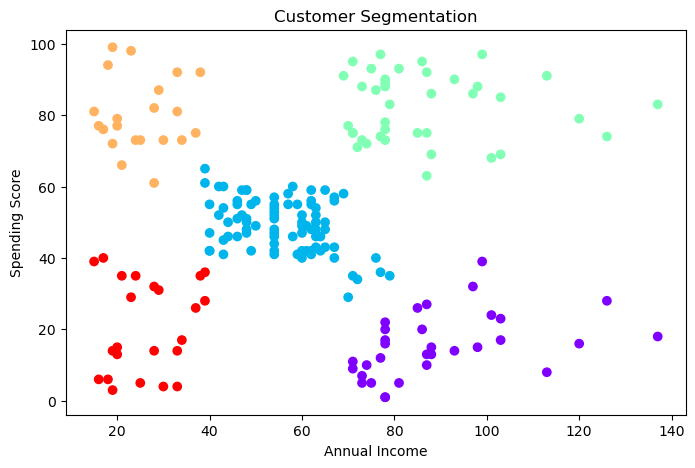

In [4]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# 2. Load dataset
df = pd.read_csv(r"C:\Users\user\OneDrive\Desktop\Mall_Customers.csv")
print(df.shape)
print(df.head())
print("Missing values:", df.isnull().sum().sum())

# 3. Select two features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# 4. Create dendrogram
Z = linkage(X, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

# 5. Apply Agglomerative Clustering
model = AgglomerativeClustering(n_clusters=5, linkage="ward")

df["Cluster"] = model.fit_predict(X)

# 6. Display cluster results
print(df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]])

# 7. Visualize clusters
plt.figure(figsize=(8, 5))

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df["Cluster"], cmap="rainbow")

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation")
plt.show()